# Dataset Cleaning for Teams Post


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import zscore
from scipy.stats import iqr


teams_post = pd.read_csv("../basketballPlayoffs/teams_post.csv")
teams_post.head()


,year,tmID,lgID,W,L
0,1,HOU,WNBA,6,0
1,1,ORL,WNBA,1,2
2,1,CLE,WNBA,3,3
3,1,WAS,WNBA,0,2
4,1,NYL,WNBA,4,3


# Check For Null Values

In [2]:
null = teams_post.isnull().values.any()
nan = teams_post.isna().values.any()

print(null)
print(nan)

# No Missing Values detected so no need of cleaning

False
False


# Dropping Unique Value Columns

In [3]:
for name in teams_post:
    for col in teams_post.columns:
        if len(teams_post[col].unique()) == 1:
            teams_post.drop(col, inplace=True, axis=1)
    print(f"Processed {name}: Remaining columns: {teams_post.columns}")


Processed year: Remaining columns: Index(['year', 'tmID', 'W', 'L'], dtype='object')
Processed tmID: Remaining columns: Index(['year', 'tmID', 'W', 'L'], dtype='object')
Processed lgID: Remaining columns: Index(['year', 'tmID', 'W', 'L'], dtype='object')
Processed W: Remaining columns: Index(['year', 'tmID', 'W', 'L'], dtype='object')
Processed L: Remaining columns: Index(['year', 'tmID', 'W', 'L'], dtype='object')


# Dealing with Redundancy

In [4]:

row_count = teams_post.shape[0]
teams_post.drop_duplicates(inplace=True)
afterDups_count = teams_post.shape[0]
rows_deleted = row_count - afterDups_count
print(f"Number of rows deleted: {rows_deleted}")


Number of rows deleted: 0


# Dealing With Outliers

`# https://www.askpython.com/python/examples/how-to-determine-outlier`

# Z-Score Implementation

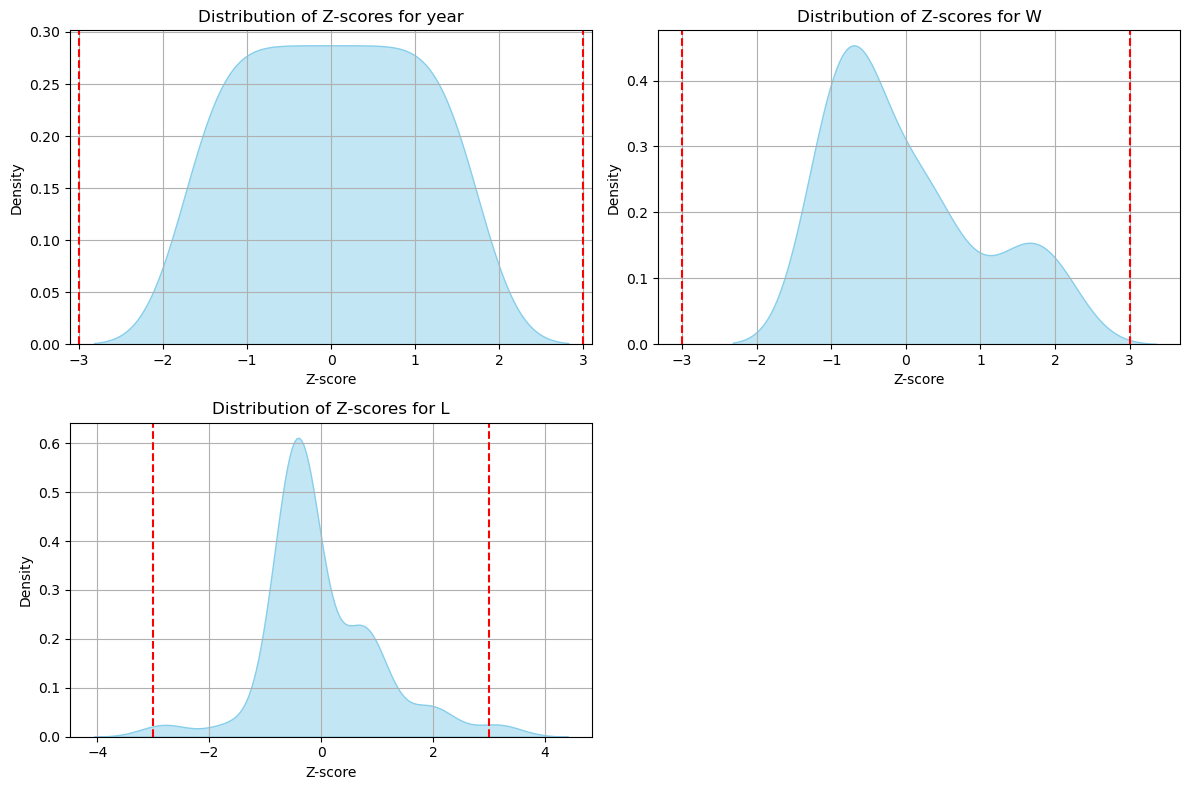

Number of outliers per column:
year    0
W       0
L       2
dtype: int64
Rows identified with any outliers: 2
Number of rows deleted: 2


In [5]:
numerical_cols = teams_post.select_dtypes(['number'])
df = numerical_cols.apply(zscore)



num_columns = 2
num_rows = (len(numerical_cols.columns) + 1) // num_columns  
fig, axes = plt.subplots(num_rows, num_columns, figsize=(12, num_rows * 4))

axes = axes.flatten()
for i, column in enumerate(numerical_cols.columns):
    sns.kdeplot(df[column], fill=True, color='skyblue', alpha=0.5, ax=axes[i])
    axes[i].set_title(f'Distribution of Z-scores for {column}')
    axes[i].set_xlabel('Z-score')
    axes[i].set_ylabel('Density')
    axes[i].grid(True)
    axes[i].axvline(x=3, color='red', linestyle='--')
    axes[i].axvline(x=-3, color='red', linestyle='--')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()


threshold = 3
outlier_mask = (df.abs() > threshold)
outliers_per_column = outlier_mask.sum()
print("Number of outliers per column:")
print(outliers_per_column)
rows_with_outliers = outlier_mask.any(axis=1)
print("Rows identified with any outliers:", rows_with_outliers.sum())


df_no_outliers = df[~rows_with_outliers]
num_rows_deleted = df.shape[0] - df_no_outliers.shape[0]
print(f"Number of rows deleted: {num_rows_deleted}")




# Interquartile Range Implementation

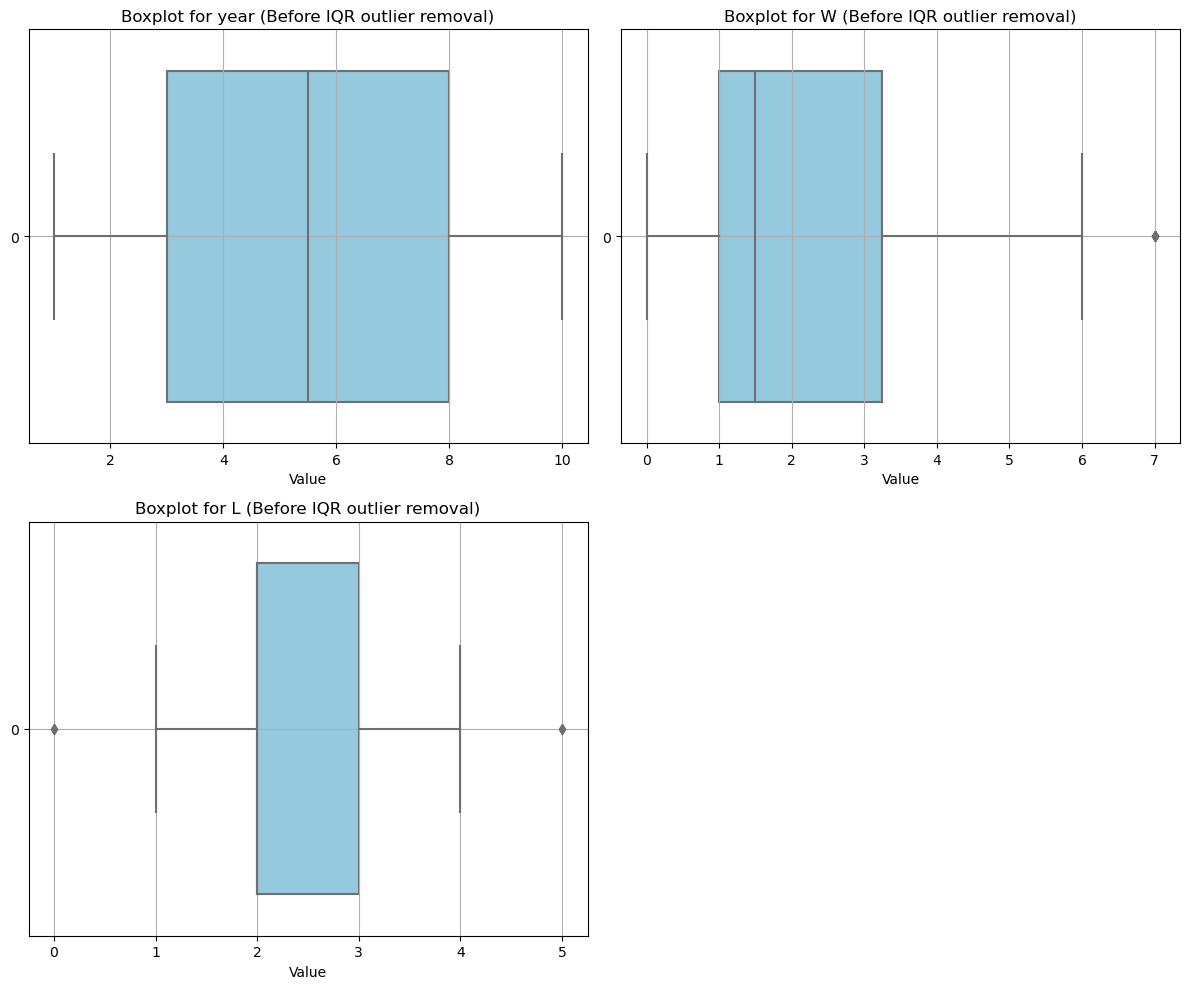

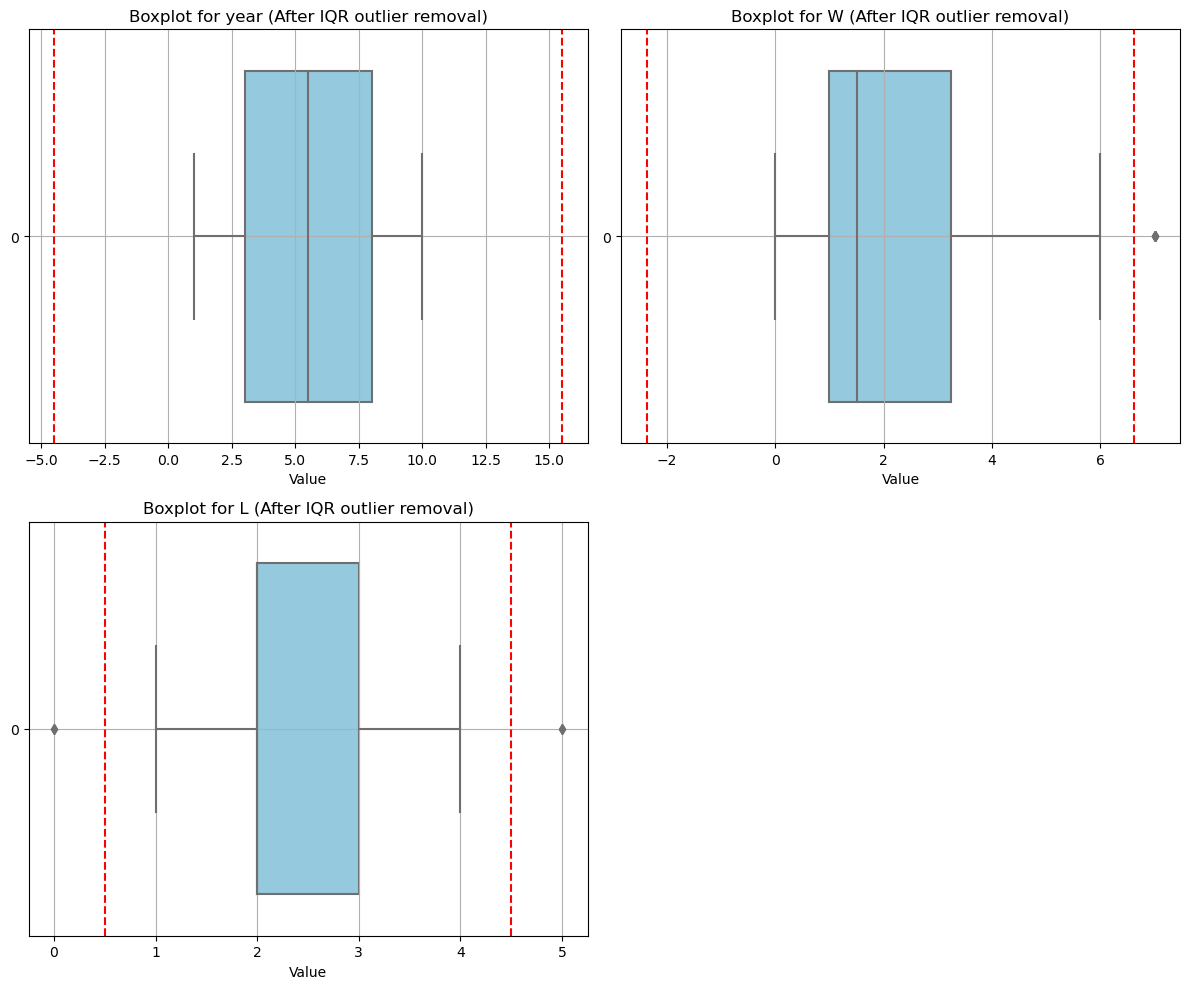

Number of rows deleted due to IQR outliers: 9


In [6]:
numerical_cols = teams_post.select_dtypes(['number'])
iqr_values = {}
lower_bounds = {}
upper_bounds = {}
outliers_iqr = pd.DataFrame(False, index=teams_post.index, columns=numerical_cols.columns)
num_columns = 2
num_rows = (len(numerical_cols.columns) + 1) // num_columns  
fig, axes = plt.subplots(num_rows, num_columns, figsize=(12, num_rows * 5))
axes = axes.flatten()

for i, column in enumerate(numerical_cols.columns):
    sns.boxplot(data=teams_post[column], ax=axes[i], color='skyblue', orient='h')
    axes[i].set_title(f'Boxplot for {column} (Before IQR outlier removal)')
    axes[i].set_xlabel('Value')
    axes[i].grid(True)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()


for column in numerical_cols.columns:
    Q1 = teams_post[column].quantile(0.25)
    Q3 = teams_post[column].quantile(0.75) 
    column_iqr = iqr(teams_post[column])  
    iqr_values[column] = column_iqr
    lower_bound = Q1 - 1.5 * column_iqr
    upper_bound = Q3 + 1.5 * column_iqr
    lower_bounds[column] = lower_bound
    upper_bounds[column] = upper_bound
    outliers_iqr[column] = (teams_post[column] < lower_bound) | (teams_post[column] > upper_bound)


num_rows_after = (len(numerical_cols.columns) + 1) // num_columns  
fig, axes = plt.subplots(num_rows_after, num_columns, figsize=(12, num_rows_after * 5))
axes = axes.flatten()

for i, column in enumerate(numerical_cols.columns):
    sns.boxplot(data=teams_post[column], ax=axes[i], color='skyblue', orient='h')
    Q1 = teams_post[column].quantile(0.25)
    Q3 = teams_post[column].quantile(0.75)
    lower_bound = lower_bounds[column]
    upper_bound = upper_bounds[column]
    
    axes[i].axvline(x=lower_bound, color='red', linestyle='--')
    axes[i].axvline(x=upper_bound, color='red', linestyle='--')
    
    axes[i].set_title(f'Boxplot for {column} (After IQR outlier removal)')
    axes[i].set_xlabel('Value')
    axes[i].grid(True)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()


rows_with_outliers = outliers_iqr.any(axis=1)
teams_post_no_outliers = teams_post[~rows_with_outliers]  


num_rows_deleted = teams_post.shape[0] - teams_post_no_outliers.shape[0]
print(f"Number of rows deleted due to IQR outliers: {num_rows_deleted}")


# Create Clean CSV

In [7]:
teams_post.to_csv('../cleaned_datasets/teams_post_cleaned.csv', index=False)